# 120 · archA-v1 vs ref: where does the factorized readout lose .056 ID?
`archA-v1` (`--readout archA --latent-dim 256`, 25.4M): per laser f_l = Σ_b W_b LN(h_b) + b (no gate); u = LN(Σ_l W_l LN(t_l) + b) + W_mask m ∈ ℝ²⁵⁶; z = W_up u → decoder.
`s9-t2-ref-vase-200` (34.9M): gated per-band pool_o, then LN + flatten + Linear(12,800 → 1024).
Sections: **1** fit vs generalization · **2** failure pattern · **3** the latent u (PCA, top-k decode, slot shuffle). fp32. Helpers copied from nb118.

In [1]:
import os, sys, math, re, json
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
GRID = {"ref": "s9-t2-ref-vase-200", "archA": "archA-v1"}
COL = {"ref": "tab:green", "archA": "tab:red"}
KEYS = ("freq_cls", "laser_cls", "band_proj", "laser_proj", "readout", "latent_dim")
ARGS = {r: {k: v for k, v in json.load(open(ROOT / "runs" / n / "args.json")).items() if k in KEYS} for r, n in GRID.items()}
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
OOD = ["rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"]
pd.DataFrame(ARGS).T

,freq_cls,laser_cls,band_proj,laser_proj,readout,latent_dim
ref,0.0,0.0,NaN,NaN,NaN,NaN
archA,0,0,0,0,archA,256


## 1 · fit vs generalization
Train = per-batch train IoU@.08 / loss from the logs (10 batches per epoch, averaged per epoch). ID / OOD recomputed per sample from the saved eval outputs at ep 0/50/100/150/200 (ID = id splits pooled with multiple, as nb113/118).

1 · fit vs generalization (train = train-batch IoU, augmented; loss = total train loss, epoch means)


,train ep50,train ep100,train ep150,train ep200,ID ep50,ID ep100,ID ep150,ID ep200,OOD ep100,OOD ep200,loss ep10,loss ep25,loss ep50,loss ep100,loss ep150,loss ep200,train-ID gap ep200,train gain ep180→200
ref,0.262,0.598,0.742,0.775,0.283,0.597,0.670,0.679,0.354,0.377,17.323,9.127,1.006,0.464,0.268,0.233,0.095,0.004
archA,0.220,0.542,0.678,0.708,0.242,0.522,0.612,0.623,0.315,0.349,17.380,5.833,1.101,0.584,0.369,0.330,0.085,0.003
archA − ref,-0.043,-0.056,-0.064,-0.066,-0.040,-0.075,-0.058,-0.056,-0.038,-0.028,0.056,-3.294,0.095,0.120,0.101,0.096,-0.010,-0.001


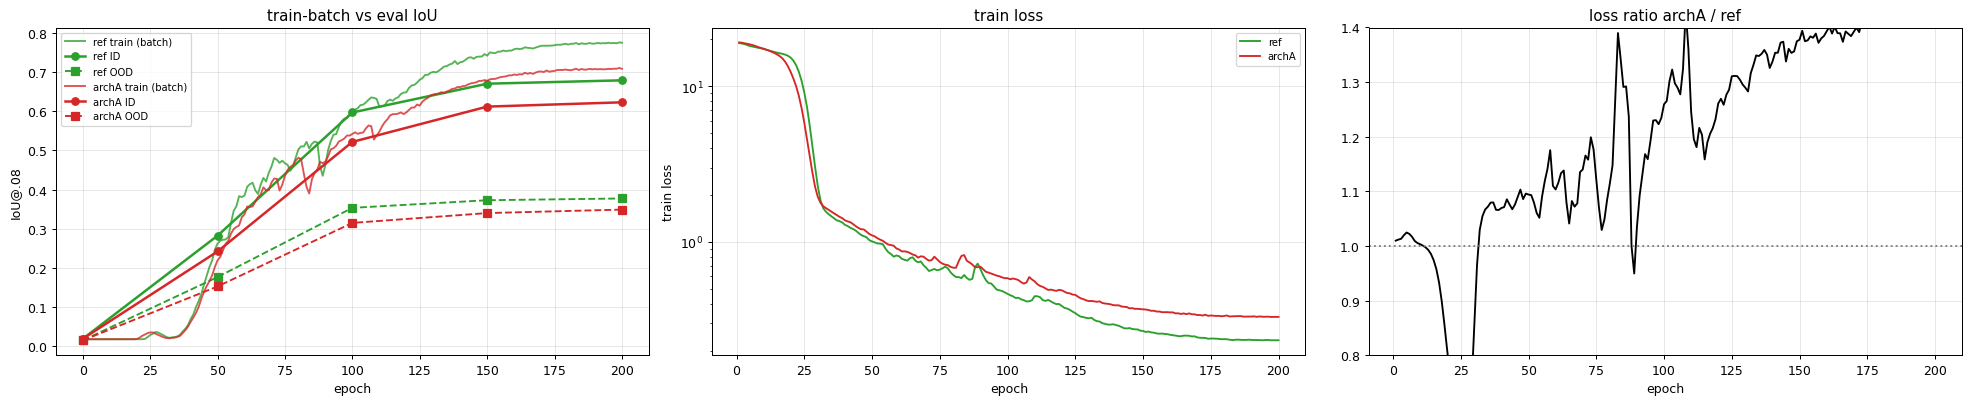

In [2]:
def sample_stats(p, y, thr=.08):
    b = p > thr; ta = y.sum()
    s = dict(iou=(b & y).sum() / max((b | y).sum(), 1), miss=float(not (b & y).any()), under=(y & ~b).sum() / ta, over=(b & ~y).sum() / ta, area_ratio=b.sum() / ta,
             precision=(b & y).sum() / max(b.sum(), 1), recall=(b & y).sum() / ta)
    if b.any():
        cy, cb = np.argwhere(y).mean(0), np.argwhere(b).mean(0); s["com_err"] = np.linalg.norm(cy - cb) / 64
        dy, dx = np.round(cy - cb).astype(int); sh = np.zeros_like(b); H, W = b.shape
        sh[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = b[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
        s["shape_iou"] = (sh & y).sum() / max((sh | y).sum(), 1)
    else: s["com_err"], s["shape_iou"] = np.nan, 0.0
    return s

def eval_frame(run, ep, full=True):
    rows = []
    for f in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
        d = torch.load(f, weights_only=False, map_location="cpu"); p, info = d["mask_pred"].float().numpy(), d["info"]
        box, split = f.parent.parent.name, f.parent.name; grp = CAT.get((box, split))
        for i in range(len(p)):
            y = score.truth(info["experiment"][i], info["sample_id"][i], int(info["position_id"][i]), int(info["speaker"][i]), *p.shape[-2:]) > .5
            if not y.any(): continue
            b = p[i] > .08
            s = sample_stats(p[i], y) if full else dict(iou=(b & y).sum() / max((b | y).sum(), 1))
            rows.append(dict(box=box, split=split, group=grp, pos=int(info["position_id"][i]), sid=info["sample_id"][i], **s))
    return pd.DataFrame(rows)
def id_ood(df): return df.iou[df.group.isin(["id", "multiple"])].mean(), df.iou[df.group.isin(OOD)].mean()
EV = {r: eval_frame(n, 200) for r, n in GRID.items()}
CURVE = {r: {ep: id_ood(eval_frame(n, ep, full=False)) for ep in (0, 50, 100, 150)} | {200: id_ood(EV[r])} for r, n in GRID.items()}

def from_log(run):
    txt = (ROOT / "runs" / run / "logs-rank0.txt").read_text()
    tr = np.array([float(v) for v in re.findall(r"Train metrics/train/iou08: ([0-9.]+)", txt)])
    loss = np.array([float(v) for v in re.findall(r"Train loss/train/total: ([0-9.]+)", txt)])
    return dict(train_iou=tr.reshape(-1, 10).mean(1), loss=loss.reshape(-1, 10).mean(1))
LOG = {r: from_log(n) for r, n in GRID.items()}

S1 = pd.DataFrame({r: {f"train ep{e}": LOG[r]["train_iou"][e - 1] for e in (50, 100, 150, 200)} | {f"ID ep{e}": CURVE[r][e][0] for e in (50, 100, 150, 200)}
                   | {f"OOD ep{e}": CURVE[r][e][1] for e in (100, 200)} | {f"loss ep{e}": LOG[r]["loss"][e - 1] for e in (10, 25, 50, 100, 150, 200)}
                   | {"train-ID gap ep200": LOG[r]["train_iou"][-10:].mean() - CURVE[r][200][0], "train gain ep180→200": LOG[r]["train_iou"][-5:].mean() - LOG[r]["train_iou"][175:180].mean()} for r in GRID}).T
S1.loc["archA − ref"] = S1.loc["archA"] - S1.loc["ref"]
print("1 · fit vs generalization (train = train-batch IoU, augmented; loss = total train loss, epoch means)"); display(S1.round(3))

fig, axs = plt.subplots(1, 3, figsize=(22, 4.6))
for r in GRID:
    e = np.arange(1, 201)
    axs[0].plot(e, LOG[r]["train_iou"], color=COL[r], alpha=.8, label=f"{r} train (batch)")
    ee = sorted(CURVE[r]); axs[0].plot(ee, [CURVE[r][k][0] for k in ee], "o-", color=COL[r], lw=2, label=f"{r} ID"); axs[0].plot(ee, [CURVE[r][k][1] for k in ee], "s--", color=COL[r], label=f"{r} OOD")
    axs[1].plot(e, LOG[r]["loss"], color=COL[r], label=r)
axs[2].plot(np.arange(1, 201), LOG["archA"]["loss"] / LOG["ref"]["loss"], color="k"); axs[2].axhline(1, color="gray", ls=":")
axs[0].set(xlabel="epoch", ylabel="IoU@.08", title="train-batch vs eval IoU"); axs[1].set(xlabel="epoch", ylabel="train loss", yscale="log", title="train loss")
axs[2].set(xlabel="epoch", title="loss ratio archA / ref", ylim=(.8, 1.4))
for ax in axs[:2]: ax.legend(fontsize=8); 
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 2 · failure pattern (all ep200 eval samples)
Per category and per split; single- vs two-object (`multiple`); CoM error vs **shape IoU** (IoU after moving the prediction onto the true CoM); over/under-painting (median pred/true area, precision, recall). Paired per sample on ID.

D1 · IoU@.08 per category (gap share = fraction of the pooled-ID loss for id/multiple)


,ref,archA,n,Δ archA−ref,gap share (n·Δ)
group,,,,,
id,0.719,0.666,2191,-0.053,0.833
multiple,0.393,0.317,310,-0.075,0.167
unseen-position,0.644,0.631,197,-0.013,0.018
rotated,0.552,0.507,166,-0.045,0.054
cylinder,0.132,0.109,331,-0.023,0.054
unseen-object,0.578,0.554,550,-0.024,0.094
unseen-speaker,0.372,0.318,85,-0.054,0.033
unseen-laser,0.208,0.183,192,-0.025,0.035
lid,0.075,0.049,83,-0.026,0.015


D1b · per box / split (ID, multiple, unseen-position)


ref  archA      Δ    n
box       split                                    
gastro    cube-vase        0.373  0.229 -0.144   27
          two-cubes        0.349  0.220 -0.129   42
cardboard two-cubes        0.358  0.276 -0.082   79
          cube             0.524  0.448 -0.077  221
          soap-dispenser   0.676  0.599 -0.077  215
plastic   cube-vase        0.463  0.392 -0.071   32
gastro    cube             0.537  0.472 -0.065  147
plastic   two-cubes        0.401  0.339 -0.062   64
          soap-dispenser   0.771  0.712 -0.058  234
gastro    soap-dispenser   0.706  0.655 -0.051  146
plastic   cube             0.649  0.599 -0.050  200
cardboard vase             0.778  0.730 -0.049  164
gastro    vase             0.772  0.727 -0.045  135
cardboard candle           0.816  0.773 -0.043  230
gastro    candle           0.814  0.773 -0.040  156
plastic   vase             0.800  0.761 -0.039  139
          candle           0.809  0.773 -0.036  204
gastro    unseen-position  0.716  0.690 -0.027   77
cardboard cube-vase        0.428  0.407 -0.020   66
          unseen-position  0.487  0.478 -0.010   52
plastic   unseen-position  0.682  0.682 -0.000   68

D1c · per object (id splits, mean over boxes)


,ref,archA,Δ
split,,,
candle,0.813,0.773,-0.040
cube,0.570,0.506,-0.064
soap-dispenser,0.718,0.656,-0.062
vase,0.783,0.739,-0.044


D2 · failure pattern (area_ratio = median pred/true area; under/over = missed/extra px over true area)


,,iou,shape_iou,com_err,miss,precision,recall,under,over,area_ratio
id,ref,0.719,0.817,0.018,0.005,0.772,0.891,0.109,0.280,1.143
multiple,ref,0.393,0.239,0.090,0.006,0.527,0.585,0.415,0.549,1.152
unseen-position,ref,0.644,0.802,0.026,0.000,0.758,0.792,0.208,0.272,1.071
OOD,ref,0.377,0.550,0.079,0.199,0.470,0.595,0.405,1.383,1.167
id,archA,0.666,0.789,0.023,0.006,0.723,0.866,0.134,0.360,1.185
multiple,archA,0.317,0.181,0.097,0.045,0.438,0.500,0.500,0.631,1.135
unseen-position,archA,0.631,0.792,0.028,0.000,0.739,0.796,0.204,0.310,1.125
OOD,archA,0.349,0.535,0.089,0.218,0.443,0.555,0.445,1.458,1.184


D3 · paired archA − ref on pooled-ID samples


,n,dIoU,dShapeIoU,dCoM_err,dPrecision,dRecall,dMiss,frac_A_worse_by_05,frac_A_better_by_05,dIoU_where_ref_good,dIoU_where_ref_bad
0,8011.0,-0.055,-0.032,0.006,-0.053,-0.032,0.005,0.495,0.189,-0.079,0.03


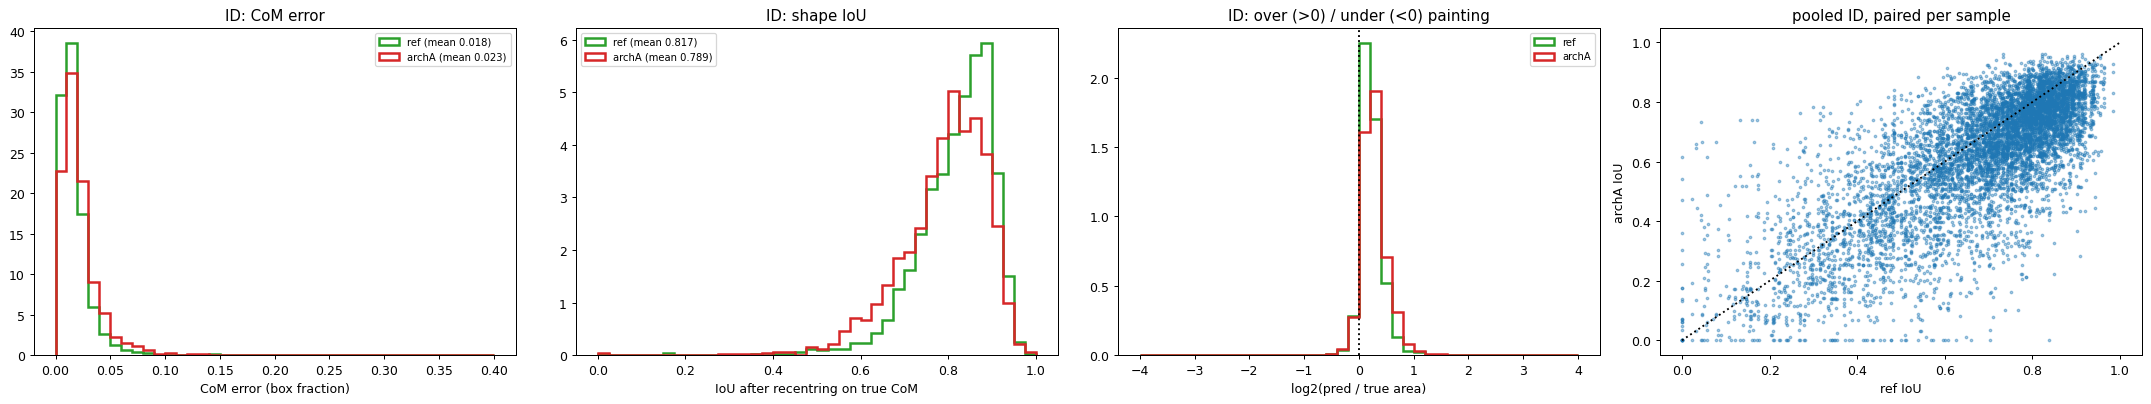

In [3]:
ORDER = ["id", "multiple", "unseen-position", *OOD]
D1 = pd.DataFrame({r: EV[r].groupby("group").iou.mean() for r in GRID}).loc[ORDER]
D1["n"] = EV["ref"].groupby("group").size().loc[ORDER]; D1["Δ archA−ref"] = D1.archA - D1.ref
D1["gap share (n·Δ)"] = D1.n * D1["Δ archA−ref"] / (D1.n * D1["Δ archA−ref"]).loc[["id", "multiple"]].sum()
print("D1 · IoU@.08 per category (gap share = fraction of the pooled-ID loss for id/multiple)"); display(D1.round(3))

idsplits = EV["ref"][EV["ref"].group.isin(["id", "multiple", "unseen-position"])]
D1b = pd.DataFrame({r: EV[r][EV[r].group.isin(["id", "multiple", "unseen-position"])].groupby(["box", "split"]).iou.mean() for r in GRID})
D1b["Δ"] = D1b.archA - D1b.ref; D1b["n"] = idsplits.groupby(["box", "split"]).size()
print("D1b · per box / split (ID, multiple, unseen-position)"); display(D1b.round(3).sort_values("Δ"))
D1c = D1b.reset_index(); D1c = D1c[~D1c.split.isin(["two-cubes", "cube-vase", "unseen-position"])].groupby("split")[["ref", "archA", "Δ"]].mean()
print("D1c · per object (id splits, mean over boxes)"); display(D1c.round(3))

met = ["iou", "shape_iou", "com_err", "miss", "precision", "recall", "under", "over", "area_ratio"]
D2 = {}
for r in GRID:
    for g in ["id", "multiple", "unseen-position", "OOD"]:
        e = EV[r]; sel = e[e.group.isin(OOD)] if g == "OOD" else e[e.group == g]
        D2[(g, r)] = {k: (sel[k].median() if k == "area_ratio" else sel[k].mean()) for k in met}
D2 = pd.DataFrame(D2).T
print("D2 · failure pattern (area_ratio = median pred/true area; under/over = missed/extra px over true area)"); display(D2.round(3))

key = ["box", "split", "pos", "sid"]
j = EV["ref"].merge(EV["archA"], on=key, suffixes=("", "_A")); j = j[j.group.isin(["id", "multiple"])]
D3 = pd.Series(dict(n=len(j), dIoU=(j.iou_A - j.iou).mean(), dShapeIoU=(j.shape_iou_A - j.shape_iou).mean(), dCoM_err=(j.com_err_A - j.com_err).mean(),
                    dPrecision=(j.precision_A - j.precision).mean(), dRecall=(j.recall_A - j.recall).mean(), dMiss=(j.miss_A - j.miss).mean(),
                    frac_A_worse_by_05=(j.iou_A < j.iou - .05).mean(), frac_A_better_by_05=(j.iou_A > j.iou + .05).mean(),
                    dIoU_where_ref_good=(j.iou_A - j.iou)[j.iou > .7].mean(), dIoU_where_ref_bad=(j.iou_A - j.iou)[j.iou < .4].mean()))
print("D3 · paired archA − ref on pooled-ID samples"); display(D3.round(3).to_frame().T)

fig, axs = plt.subplots(1, 4, figsize=(24, 4.6))
for r in GRID:
    e = EV[r][EV[r].group == "id"]
    axs[0].hist(e.com_err.dropna(), np.linspace(0, .4, 41), histtype="step", lw=2, color=COL[r], label=f"{r} (mean {e.com_err.mean():.3f})", density=True)
    axs[1].hist(e.shape_iou, np.linspace(0, 1, 41), histtype="step", lw=2, color=COL[r], label=f"{r} (mean {e.shape_iou.mean():.3f})", density=True)
    axs[2].hist(np.log2(e.area_ratio.clip(1 / 16, 16)), np.linspace(-4, 4, 41), histtype="step", lw=2, color=COL[r], label=r, density=True)
axs[3].scatter(j.iou, j.iou_A, s=4, alpha=.4); axs[3].plot([0, 1], [0, 1], "k:")
axs[0].set(xlabel="CoM error (box fraction)", title="ID: CoM error"); axs[1].set(xlabel="IoU after recentring on true CoM", title="ID: shape IoU")
axs[2].set(xlabel="log2(pred / true area)", title="ID: over (>0) / under (<0) painting"); axs[2].axvline(0, color="k", ls=":")
axs[3].set(xlabel="ref IoU", ylabel="archA IoU", title="pooled ID, paired per sample")
for ax in axs[:3]: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3 · the latent u
Load both checkpoints; 300 train + 300 ID + 100 unseen-position samples. `encode` = the real forward with a hook to shuffle the laser content between slots (each slot keeps its laser embedding; nb118 B3). Latent = u (256-d) for archA, the 1024-d decoder input for ref (archA's 1024-d z = W_up u also shown).

In [4]:
NAMES = None
SD = {r: torch.load(ROOT / f"runs/{n}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"] for r, n in GRID.items()}
def build(r):
    sd = SD[r]; nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, **ARGS[r]); m.load_state_dict(sd, strict=True); return m.eval().to(DEV)

ev = {"id": [], "unseen-position": []}
for f in sorted((ROOT / f"runs/{GRID['ref']}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    c = CAT.get((f.parent.parent.name, f.parent.name)); c = "id" if c == "multiple" else c
    if c not in ev: continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    ev[c] += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
samples, idxs = D9.load_splits(); metas = list(samples.values())
tr = [(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, int(m["position_id"]), int(m["speaker"])) for m in (metas[i] for i in idxs["train"]) if m["n_objects"] > 0]
pick = lambda L, n: [L[i] for i in np.random.choice(len(L), n, replace=False)]
SEL = [("train", s) for s in pick(tr, 300)] + [("id", s) for s in pick(ev["id"], 300)] + [("unseen-position", s) for s in pick(ev["unseen-position"], 100)]
X, BOXN, Y = [], [], []
for _, (exp, sid, pos, spk) in SEL:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float()); BOXN.append(meta["box"]); Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y = torch.stack(X), np.stack(Y); N = len(SEL); GROUP = np.array([g for g, _ in SEL])
NAMES = sorted(set(BOXN)); BOX = torch.tensor([NAMES.index(b) for b in BOXN])
TR, ID, UP = [np.where(GROUP == g)[0] for g in ["train", "id", "unseen-position"]]
M = {r: build(r) for r in GRID}

@torch.no_grad()
def encode(m, x, bx, perm=None):
    e, le = m.encoder, m.encoder.laser_enc; B = len(x); A = e.readout == "archA"
    ml, mb = (x.new_ones(B, e.L), x.new_ones(B, e.n_bands)) if A else (None, None)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)
    t = e.freq_enc(e.normalize(x, bx), bx, e.freq_band_logf, laser, mb)                # (B,L,d) per-laser token
    if perm is not None: t = t[:, perm]                                               # slot l gets laser perm[l]'s content
    emb = le(t + laser, ml, mb)
    out = dict(emb=emb, mask=m.decoder(emb)[:, 0].sigmoid())
    if A: out["u"] = le.last_u
    return out
def run(m, idx=None, bs=50, **kw):
    idx = np.arange(N) if idx is None else np.asarray(idx); outs = []
    for i in range(0, len(idx), bs): outs.append({k: v.cpu() for k, v in encode(m, X[idx[i:i + bs]].to(DEV), BOX[idx[i:i + bs]].to(DEV), **kw).items()})
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}
def iou(P, idx, thr=.08): return np.array([((P[j] > thr) & (Y[i] > .5)).sum() / max(((P[j] > thr) | (Y[i] > .5)).sum(), 1) for j, i in enumerate(idx)])
with torch.no_grad():
    for r, m in M.items(): assert torch.allclose(m.decoder(m.encoder(X[:4].to(DEV), BOX[:4].to(DEV)))[:, 0].sigmoid().cpu(), run(m, np.arange(4))["mask"], atol=1e-4), r
O = {r: run(m) for r, m in M.items()}
print("IoU@.08 on these samples"); display(pd.DataFrame({r: {g: iou(O[r]["mask"][ix].numpy(), ix).mean() for g, ix in [("train", TR), ("id", ID), ("unseen-pos", UP)]} for r in GRID}).T.round(3))

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


IoU@.08 on these samples


,train,id,unseen-pos
ref,0.819,0.685,0.641
archA,0.766,0.620,0.627


A1 · PCA spectrum over all 700 samples


,part_ratio,k50,k90,k99
ref emb (1024),26.851097,11.0,70.0,314.0
archA u (256),38.246136,14.0,101.0,213.0
archA z=W_up u (1024),31.365812,11.0,80.0,195.0


A2 · ID IoU@.08 after projecting the latent onto its top-k PCs (fit on train samples), decoded


,4,8,16,32,64,128,256
ref emb (1024),0.146,0.231,0.351,0.496,0.621,0.661,0.673
archA u (256),0.045,0.118,0.230,0.386,0.494,0.571,0.620


B3 · shuffle which laser slot each per-laser token sits in (3 permutations)


,IoU_as_trained,IoU_slots_shuffled
ref,0.685,0.045
archA,0.620,0.058


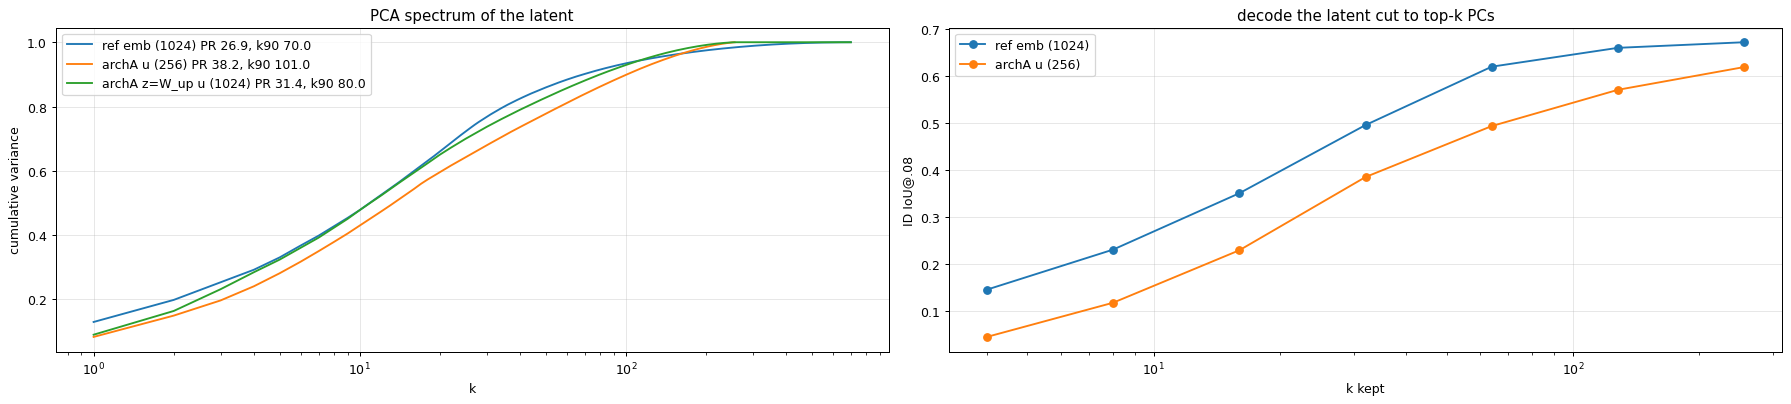

In [5]:
def pca(Z, fit_idx):
    mu = Z[fit_idx].mean(0); U, s, Vt = torch.linalg.svd((Z[fit_idx] - mu).double(), full_matrices=False)
    return mu, Vt.float(), (s ** 2 / (len(fit_idx) - 1)).float()
def spectrum_stats(v):
    c = (v / v.sum()).cumsum(0)
    return dict(part_ratio=(v.sum() ** 2 / (v ** 2).sum()).item(), k50=int((c < .5).sum()) + 1, k90=int((c < .9).sum()) + 1, k99=int((c < .99).sum()) + 1)
LAT = {"ref emb (1024)": ("ref", "emb"), "archA u (256)": ("archA", "u"), "archA z=W_up u (1024)": ("archA", "emb")}
SPEC = {k: pca(O[r][f], np.arange(N))[2] for k, (r, f) in LAT.items()}
A1 = pd.DataFrame({k: spectrum_stats(v) for k, v in SPEC.items()}).T
print("A1 · PCA spectrum over all 700 samples"); display(A1)

KS = [4, 8, 16, 32, 64, 128, 256, 1024]
A2 = {}
for k_, (r, f) in [("ref emb (1024)", ("ref", "emb")), ("archA u (256)", ("archA", "u"))]:
    Z = O[r][f]; mu, V, _ = pca(Z, TR); A2[k_] = {}; le = M[r].encoder.laser_enc
    for k in KS:
        if k > len(V): continue
        Zk = mu + (Z - mu) @ V[:k].T @ V[:k]
        with torch.no_grad(): P = torch.cat([M[r].decoder((le.w_up(Zk[i:i + 100].to(DEV)) if f == "u" else Zk[i:i + 100].to(DEV)))[:, 0].sigmoid().cpu() for i in range(0, N, 100)]).numpy()
        A2[k_][k] = iou(P[ID], ID).mean()
A2 = pd.DataFrame(A2).T
print("A2 · ID IoU@.08 after projecting the latent onto its top-k PCs (fit on train samples), decoded"); display(A2.round(3))

g = torch.Generator().manual_seed(0); PERMS = [torch.randperm(100, generator=g) for _ in range(3)]
B3 = pd.DataFrame({r: dict(IoU_as_trained=iou(O[r]["mask"][ID].numpy(), ID).mean(), IoU_slots_shuffled=np.mean([iou(run(M[r], ID, perm=p)["mask"].numpy(), ID).mean() for p in PERMS])) for r in GRID}).T
print("B3 · shuffle which laser slot each per-laser token sits in (3 permutations)"); display(B3.round(3))

fig, axs = plt.subplots(1, 2, figsize=(20, 4.6))
for k_, v in SPEC.items(): axs[0].plot(np.arange(1, len(v) + 1), (v / v.sum()).cumsum(0), label=f"{k_} PR {A1.loc[k_, 'part_ratio']:.1f}, k90 {A1.loc[k_, 'k90']}")
for k_ in A2.index: axs[1].plot(A2.columns, A2.loc[k_], "o-", label=k_)
axs[0].set(xscale="log", xlabel="k", ylabel="cumulative variance", title="PCA spectrum of the latent"); axs[1].set(xscale="log", xlabel="k kept", ylabel="ID IoU@.08", title="decode the latent cut to top-k PCs")
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Summary
1. **Underfit, not overfit.** Train-batch IoU at ep200 is .708 vs .775 (−.066), the same size as the ID gap (−.056). The train−ID gap is similar (.085 vs .095), and both runs are flat at the end (+.003/.004 over the last 20 ep).
2. **It plateaus lower; it does not start slower.** Loss at ep25 is *lower* for archA (5.8 vs 9.1). From ep50 on it is higher by about 0.1 absolute (+9% at ep50, +26% at ep100, +42% at ep200), and the ratio keeps growing as the LR anneals. That points to a capacity/expressivity limit, not an LR/schedule problem.
3. **The gap is in-distribution fit.** Pooled ID −.056 (id −.053, multiple −.075); unseen-position only −.013 and OOD −.028. Hardest hit: two-object scenes (gastro cube-vase −.14, two-cubes −.13) and cube/soap (−.06), less so candle/vase (−.04). It is mostly worse on samples ref already gets right (Δ −.08 where ref IoU > .7; +.03 where ref < .4).
4. **Shape more than location.** Paired ID: ΔshapeIoU −.032, ΔCoM +.006 (.018 → .023). Slight over-painting: precision −.053, recall −.032, over 0.28 → 0.36, median area ratio 1.14 → 1.19.
5. **u fills its 256 dims.** PR 38 vs ref's 27; k90 101, k99 213 of 256. Decoding top-k PCs: archA needs all 256 (k=64 .49, k=256 .62). Ref keeps .673 at k=256 (vs .685 full), so a 256-d bound by itself costs only ~.01. archA's 256 dims hold less useful information than ref's top 256.
6. **Slot shuffle collapses both** (ref .045, archA .058): archA is just as slot-indexed as ref.